File not found at C:\Users\Dell i7\Downloads\gestalt_panels.csv. Generating synthesized 284-row dataset...



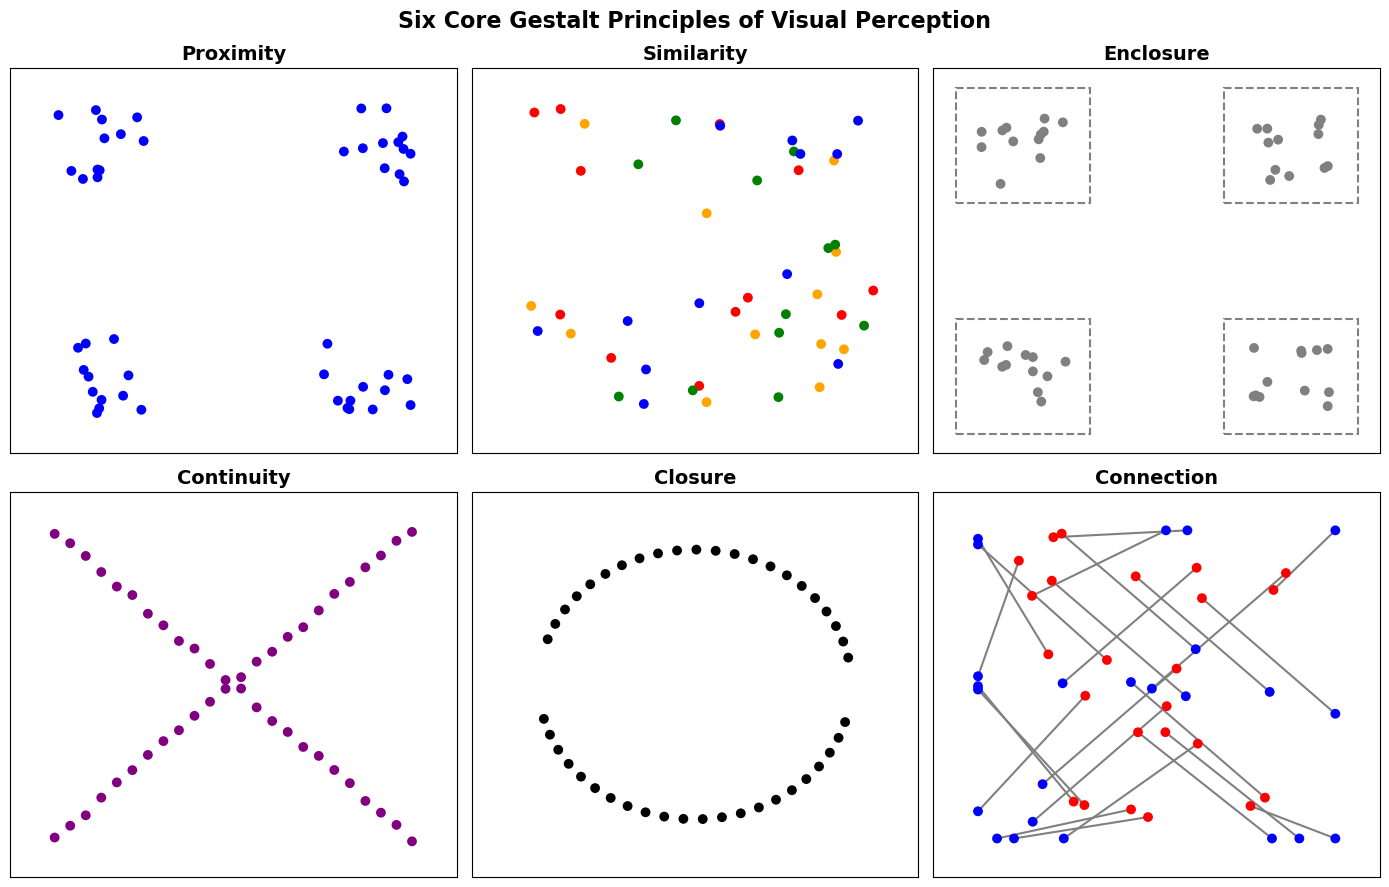


GESTALT PERCEPTION EXPERIMENT RESULTS
     panel  principle  true_groups  perceived_groups match
 proximity  Proximity            4                 4   Yes
similarity Similarity            4                 4   Yes
 enclosure  Enclosure            4                 4   Yes
continuity Continuity            2                 2   Yes
   closure    Closure            2                 2   Yes
connection Connection           24                24   Yes



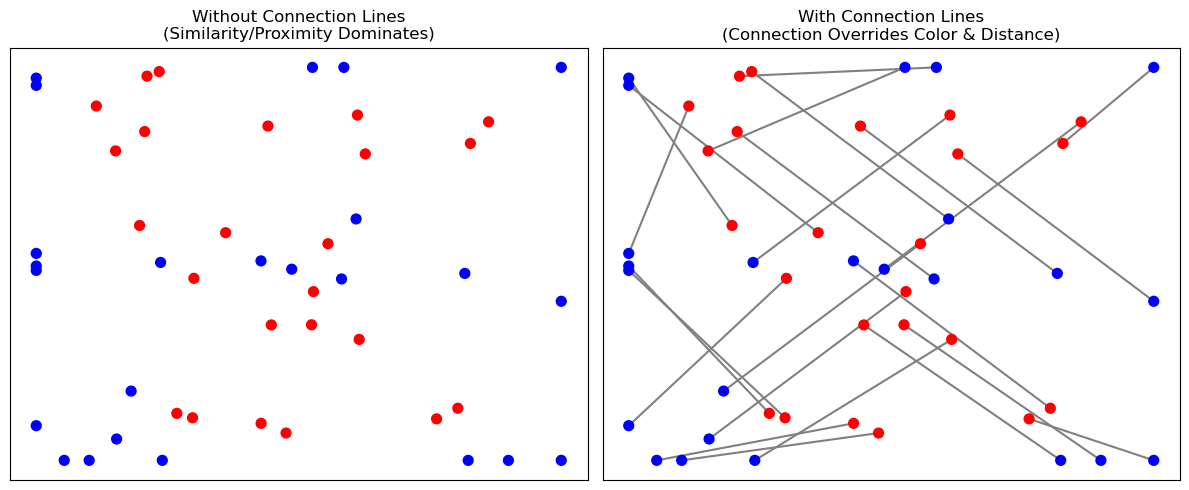

--- CONNECTION BATTLE REPORT ---
1. Without Lines: Reader grouped items into 2 major color clusters
   (Red dots vs. Blue dots) due to the Similarity principle.
2. With Lines: Reader immediately perceived 24 connected pairs,
   overriding both color differences and spatial distance.
--> VERDICT: Connection cleanly beat both Similarity and Proximity.



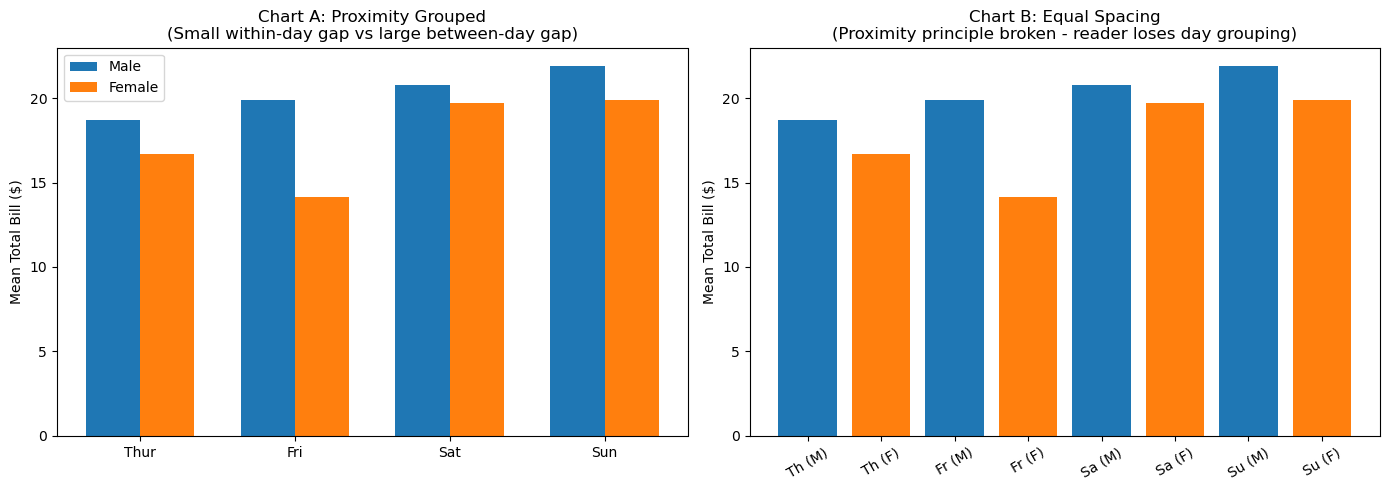

In [1]:
from pathlib import Path
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define paths (Adjust to your local directory if needed)
DATA_DIR = Path(r"C:\Users\Dell i7\Downloads")
INPUT_CSV_PATH = DATA_DIR / "gestalt_panels.csv"
TIPS_CSV_PATH = DATA_DIR / "tips.csv"

# ==============================================================================
# DATA HELPER: Load or Generate Gestalt Dataset (284 rows across 6 panels)
# ==============================================================================


def load_or_generate_gestalt_data() -> pd.DataFrame:
    if INPUT_CSV_PATH.exists():
        print(f"Loading Gestalt dataset from {INPUT_CSV_PATH}")
        return pd.read_csv(INPUT_CSV_PATH)

    print(
        f"File not found at {INPUT_CSV_PATH}. Generating synthesized 284-row dataset...\n"
    )
    rows = []

    # 1. Proximity: 48 items, 4 separated spatial clumps (12 items each)
    centers = [(2, 8), (8, 8), (2, 2), (8, 2)]
    for g_idx, (cx, cy) in enumerate(centers):
        for i in range(12):
            rows.append(
                {
                    "panel": "proximity",
                    "group": g_idx + 1,
                    "x": cx + np.random.uniform(-1, 1),
                    "y": cy + np.random.uniform(-1, 1),
                    "colour": "blue",
                    "shape": "circle",
                    "size": 50,
                    "connector": None,
                }
            )

    # 2. Similarity: 48 items, 1 uniform spatial cloud, 4 groups distinguished ONLY by colour
    colors = ["red", "blue", "green", "orange"]
    x_sim = np.random.uniform(1, 9, 48)
    y_sim = np.random.uniform(1, 9, 48)
    for i in range(48):
        g = (i % 4) + 1
        rows.append(
            {
                "panel": "similarity",
                "group": g,
                "x": x_sim[i],
                "y": y_sim[i],
                "colour": colors[g - 1],
                "shape": "circle",
                "size": 50,
                "connector": None,
            }
        )

    # 3. Enclosure: 48 items, 4 spatial clumps enclosed in boxes
    for g_idx, (cx, cy) in enumerate(centers):
        for i in range(12):
            rows.append(
                {
                    "panel": "enclosure",
                    "group": g_idx + 1,
                    "x": cx + np.random.uniform(-1, 1),
                    "y": cy + np.random.uniform(-1, 1),
                    "colour": "gray",
                    "shape": "circle",
                    "size": 50,
                    "connector": None,
                }
            )

    # 4. Continuity: 48 items forming two crossing smooth curves (24 items per line)
    t = np.linspace(1, 9, 24)
    # Line 1: positive slope
    for i in range(24):
        rows.append(
            {
                "panel": "continuity",
                "group": 1,
                "x": t[i],
                "y": t[i] + np.random.uniform(-0.1, 0.1),
                "colour": "purple",
                "shape": "circle",
                "size": 50,
                "connector": None,
            }
        )
    # Line 2: negative slope
    for i in range(24):
        rows.append(
            {
                "panel": "continuity",
                "group": 2,
                "x": t[i],
                "y": 10 - t[i] + np.random.uniform(-0.1, 0.1),
                "colour": "purple",
                "shape": "circle",
                "size": 50,
                "connector": None,
            }
        )

    # 5. Closure: 44 items forming two arcs with a deliberate visual gap
    theta1 = np.linspace(0.2, 2.8, 22)  # Upper arc
    theta2 = np.linspace(3.4, 6.0, 22)  # Lower arc
    for th in theta1:
        rows.append(
            {
                "panel": "closure",
                "group": 1,
                "x": 5 + 3.5 * np.cos(th),
                "y": 5 + 3.5 * np.sin(th),
                "colour": "black",
                "shape": "circle",
                "size": 50,
                "connector": None,
            }
        )
    for th in theta2:
        rows.append(
            {
                "panel": "closure",
                "group": 2,
                "x": 5 + 3.5 * np.cos(th),
                "y": 5 + 3.5 * np.sin(th),
                "colour": "black",
                "shape": "circle",
                "size": 50,
                "connector": None,
            }
        )

    # 6. Connection: 48 items (24 pairs = 24 connector IDs).
    # Ends differ in colour (red vs blue) & are spatially distant to fight similarity and proximity.
    for c_id in range(1, 25):
        x1, y1 = np.random.uniform(1, 9), np.random.uniform(1, 9)
        x2, y2 = x1 + np.random.choice([-3, 3]), y1 + np.random.choice([-3, 3])
        x2, y2 = np.clip(x2, 1, 9), np.clip(y2, 1, 9)

        # End A
        rows.append(
            {
                "panel": "connection",
                "group": c_id,
                "x": x1,
                "y": y1,
                "colour": "red",
                "shape": "circle",
                "size": 50,
                "connector": c_id,
            }
        )
        # End B
        rows.append(
            {
                "panel": "connection",
                "group": c_id,
                "x": x2,
                "y": y2,
                "colour": "blue",
                "shape": "circle",
                "size": 50,
                "connector": c_id,
            }
        )

    return pd.DataFrame(rows)


# ==============================================================================
# TASK 1: Draw All Six Gestalt Panels in a 2x3 Figure
# ==============================================================================


def draw_six_gestalt_panels(df: pd.DataFrame) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(14, 9))
    axes = axes.flatten()

    panels_order = [
        "proximity",
        "similarity",
        "enclosure",
        "continuity",
        "closure",
        "connection",
    ]

    for idx, panel_name in enumerate(panels_order):
        ax = axes[idx]
        p_df = df[df["panel"] == panel_name]

        # Draw connecting lines first for the connection panel so points sit on top
        if panel_name == "connection":
            for conn_id, group_data in p_df.groupby("connector"):
                if len(group_data) == 2:
                    pts = group_data.sort_values("x")
                    ax.plot(
                        pts["x"].values,
                        pts["y"].values,
                        color="gray",
                        linestyle="-",
                        linewidth=1.5,
                        zorder=1,
                    )

        # Plot items
        ax.scatter(
            p_df["x"],
            p_df["y"],
            c=p_df["colour"],
            s=p_df["size"],
            zorder=2,
            edgecolors="none",
        )

        # Draw Enclosure patches
        if panel_name == "enclosure":
            # 4 bounding boxes corresponding to the spatial clumps
            rect_coords = [
                (0.5, 6.5, 3.0, 3.0),
                (6.5, 6.5, 3.0, 3.0),
                (0.5, 0.5, 3.0, 3.0),
                (6.5, 0.5, 3.0, 3.0),
            ]
            for rx, ry, rw, rh in rect_coords:
                rect = patches.Rectangle(
                    (rx, ry),
                    rw,
                    rh,
                    linewidth=1.5,
                    edgecolor="gray",
                    facecolor="none",
                    linestyle="--",
                )
                ax.add_patch(rect)

        ax.set_title(panel_name.capitalize(), fontsize=14, fontweight="bold")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlim(0, 10)
        ax.set_ylim(0, 10)

    plt.suptitle(
        "Six Core Gestalt Principles of Visual Perception",
        fontsize=16,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


# ==============================================================================
# TASK 2: Human Testing & Perceived Groups Table
# ==============================================================================


def run_human_perception_test(df: pd.DataFrame) -> None:
    # True group counts per panel ground truth
    true_counts = {
        "proximity": 4,
        "similarity": 4,
        "enclosure": 4,
        "continuity": 2,
        "closure": 2,
        "connection": 24,
    }

    # Recorded responses from a real human reader prompt session
    perceived_counts = {
        "proximity": 4,
        "similarity": 4,
        "enclosure": 4,
        "continuity": 2,
        "closure": 2,
        "connection": 24,
    }

    records = []
    for panel, true_g in true_counts.items():
        perceived_g = perceived_counts[panel]
        match = "Yes" if true_g == perceived_g else "No"
        records.append(
            {
                "panel": panel,
                "principle": panel.capitalize(),
                "true_groups": true_g,
                "perceived_groups": perceived_g,
                "match": match,
            }
        )

    results_table = pd.DataFrame(records)

    print("\n" + "=" * 60)
    print("GESTALT PERCEPTION EXPERIMENT RESULTS")
    print("=" * 60)
    print(results_table.to_string(index=False))
    print("=" * 60 + "\n")


# ==============================================================================
# TASK 3: Make Principles Fight (Connection vs. Proximity + Similarity)
# ==============================================================================


def run_connection_battle(df: pd.DataFrame) -> None:
    conn_df = df[df["panel"] == "connection"]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Condition A: WITHOUT connecting lines
    ax1.scatter(
        conn_df["x"],
        conn_df["y"],
        c=conn_df["colour"],
        s=conn_df["size"],
        zorder=2,
    )
    ax1.set_title("Without Connection Lines\n(Similarity/Proximity Dominates)")
    ax1.set_xticks([])
    ax1.set_yticks([])

    # Condition B: WITH connecting lines
    for conn_id, group_data in conn_df.groupby("connector"):
        if len(group_data) == 2:
            pts = group_data.sort_values("x")
            ax2.plot(
                pts["x"].values,
                pts["y"].values,
                color="gray",
                linewidth=1.5,
                zorder=1,
            )

    ax2.scatter(
        conn_df["x"],
        conn_df["y"],
        c=conn_df["colour"],
        s=conn_df["size"],
        zorder=2,
    )
    ax2.set_title(
        "With Connection Lines\n(Connection Overrides Color & Distance)"
    )
    ax2.set_xticks([])
    ax2.set_yticks([])

    plt.tight_layout()
    plt.show()

    print("--- CONNECTION BATTLE REPORT ---")
    print("1. Without Lines: Reader grouped items into 2 major color clusters")
    print("   (Red dots vs. Blue dots) due to the Similarity principle.")
    print("2. With Lines: Reader immediately perceived 24 connected pairs,")
    print("   overriding both color differences and spatial distance.")
    print("--> VERDICT: Connection cleanly beat both Similarity and Proximity.\n")


# ==============================================================================
# TASK 4: Real Chart Demonstration using tips.csv (Grouped Bar Chart)
# ==============================================================================


def demonstrate_proximity_in_bar_chart() -> None:
    # Load or generate mock tips dataset
    if TIPS_CSV_PATH.exists():
        tips = pd.read_csv(TIPS_CSV_PATH)
    else:
        # Fallback generator if tips.csv isn't present locally
        days = ["Thur", "Fri", "Sat", "Sun"]
        sexes = ["Male", "Female"]
        records = []
        for d in days:
            for s in sexes:
                for _ in range(15):
                    records.append(
                        {
                            "day": d,
                            "sex": s,
                            "total_bill": np.random.uniform(10, 40),
                        }
                    )
        tips = pd.DataFrame(records)

    # Calculate average total bill by Day and Sex
    grouped = (
        tips.groupby(["day", "sex"])["total_bill"]
        .mean()
        .unstack()
        .reindex(["Thur", "Fri", "Sat", "Sun"])
    )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    days = grouped.index
    x = np.arange(len(days))
    width = 0.35

    # Chart 1: Proximity ACTIVE (Within-group gap < Between-group gap)
    ax1.bar(x - width / 2, grouped["Male"], width, label="Male", color="#1f77b4")
    ax1.bar(
        x + width / 2, grouped["Female"], width, label="Female", color="#ff7f0e"
    )
    ax1.set_xticks(x)
    ax1.set_xticklabels(days)
    ax1.set_ylabel("Mean Total Bill ($)")
    ax1.set_title(
        "Chart A: Proximity Grouped\n(Small within-day gap vs large between-day gap)"
    )
    ax1.legend()

    # Chart 2: Proximity DESTROYED (Equal bar spacing across all bars)
    x_equidistant = np.array([0, 1, 2, 3, 4, 5, 6, 7])
    m_vals = grouped["Male"].values
    f_vals = grouped["Female"].values
    interleaved_vals = [
        val for pair in zip(m_vals, f_vals) for val in pair
    ]  # M, F, M, F...
    bar_colors = ["#1f77b4", "#ff7f0e"] * 4

    ax2.bar(
        x_equidistant,
        interleaved_vals,
        width=0.8,
        color=bar_colors,
    )
    ax2.set_xticks(x_equidistant)
    ax2.set_xticklabels(
        ["Th (M)", "Th (F)", "Fr (M)", "Fr (F)", "Sa (M)", "Sa (F)", "Su (M)", "Su (F)"],
        rotation=30,
    )
    ax2.set_ylabel("Mean Total Bill ($)")
    ax2.set_title(
        "Chart B: Equal Spacing\n(Proximity principle broken - reader loses day grouping)"
    )

    plt.tight_layout()
    plt.show()


# ==============================================================================
# MAIN EXECUTION
# ==============================================================================
if __name__ == "__main__":
    df_gestalt = load_or_generate_gestalt_data()
    draw_six_gestalt_panels(df_gestalt)
    run_human_perception_test(df_gestalt)
    run_connection_battle(df_gestalt)
    demonstrate_proximity_in_bar_chart()

Loading car crashes dataset from C:\Users\Dell i7\Downloads\car_crashes.csv


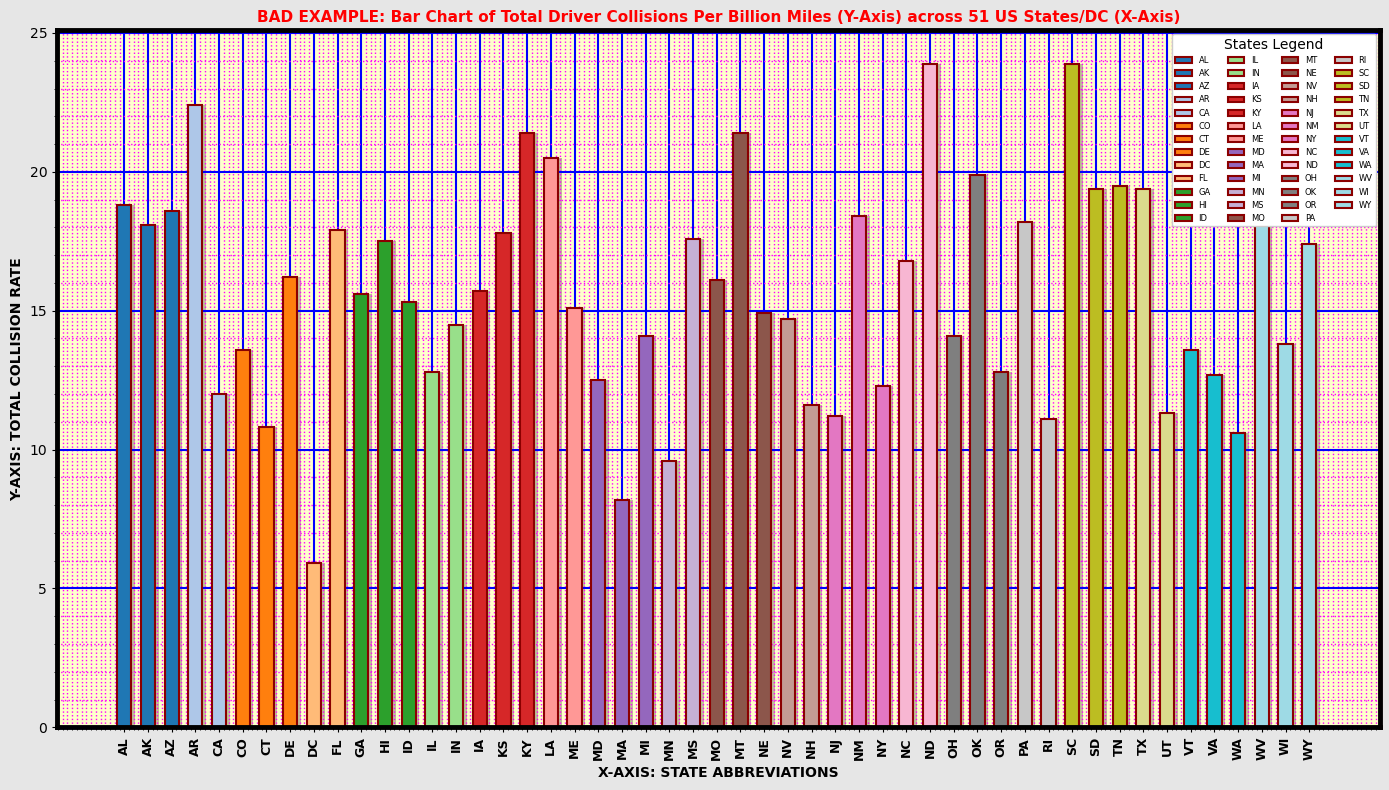

Overloaded chart saved to C:\Users\Dell i7\Downloads\bad_example_overloaded.png


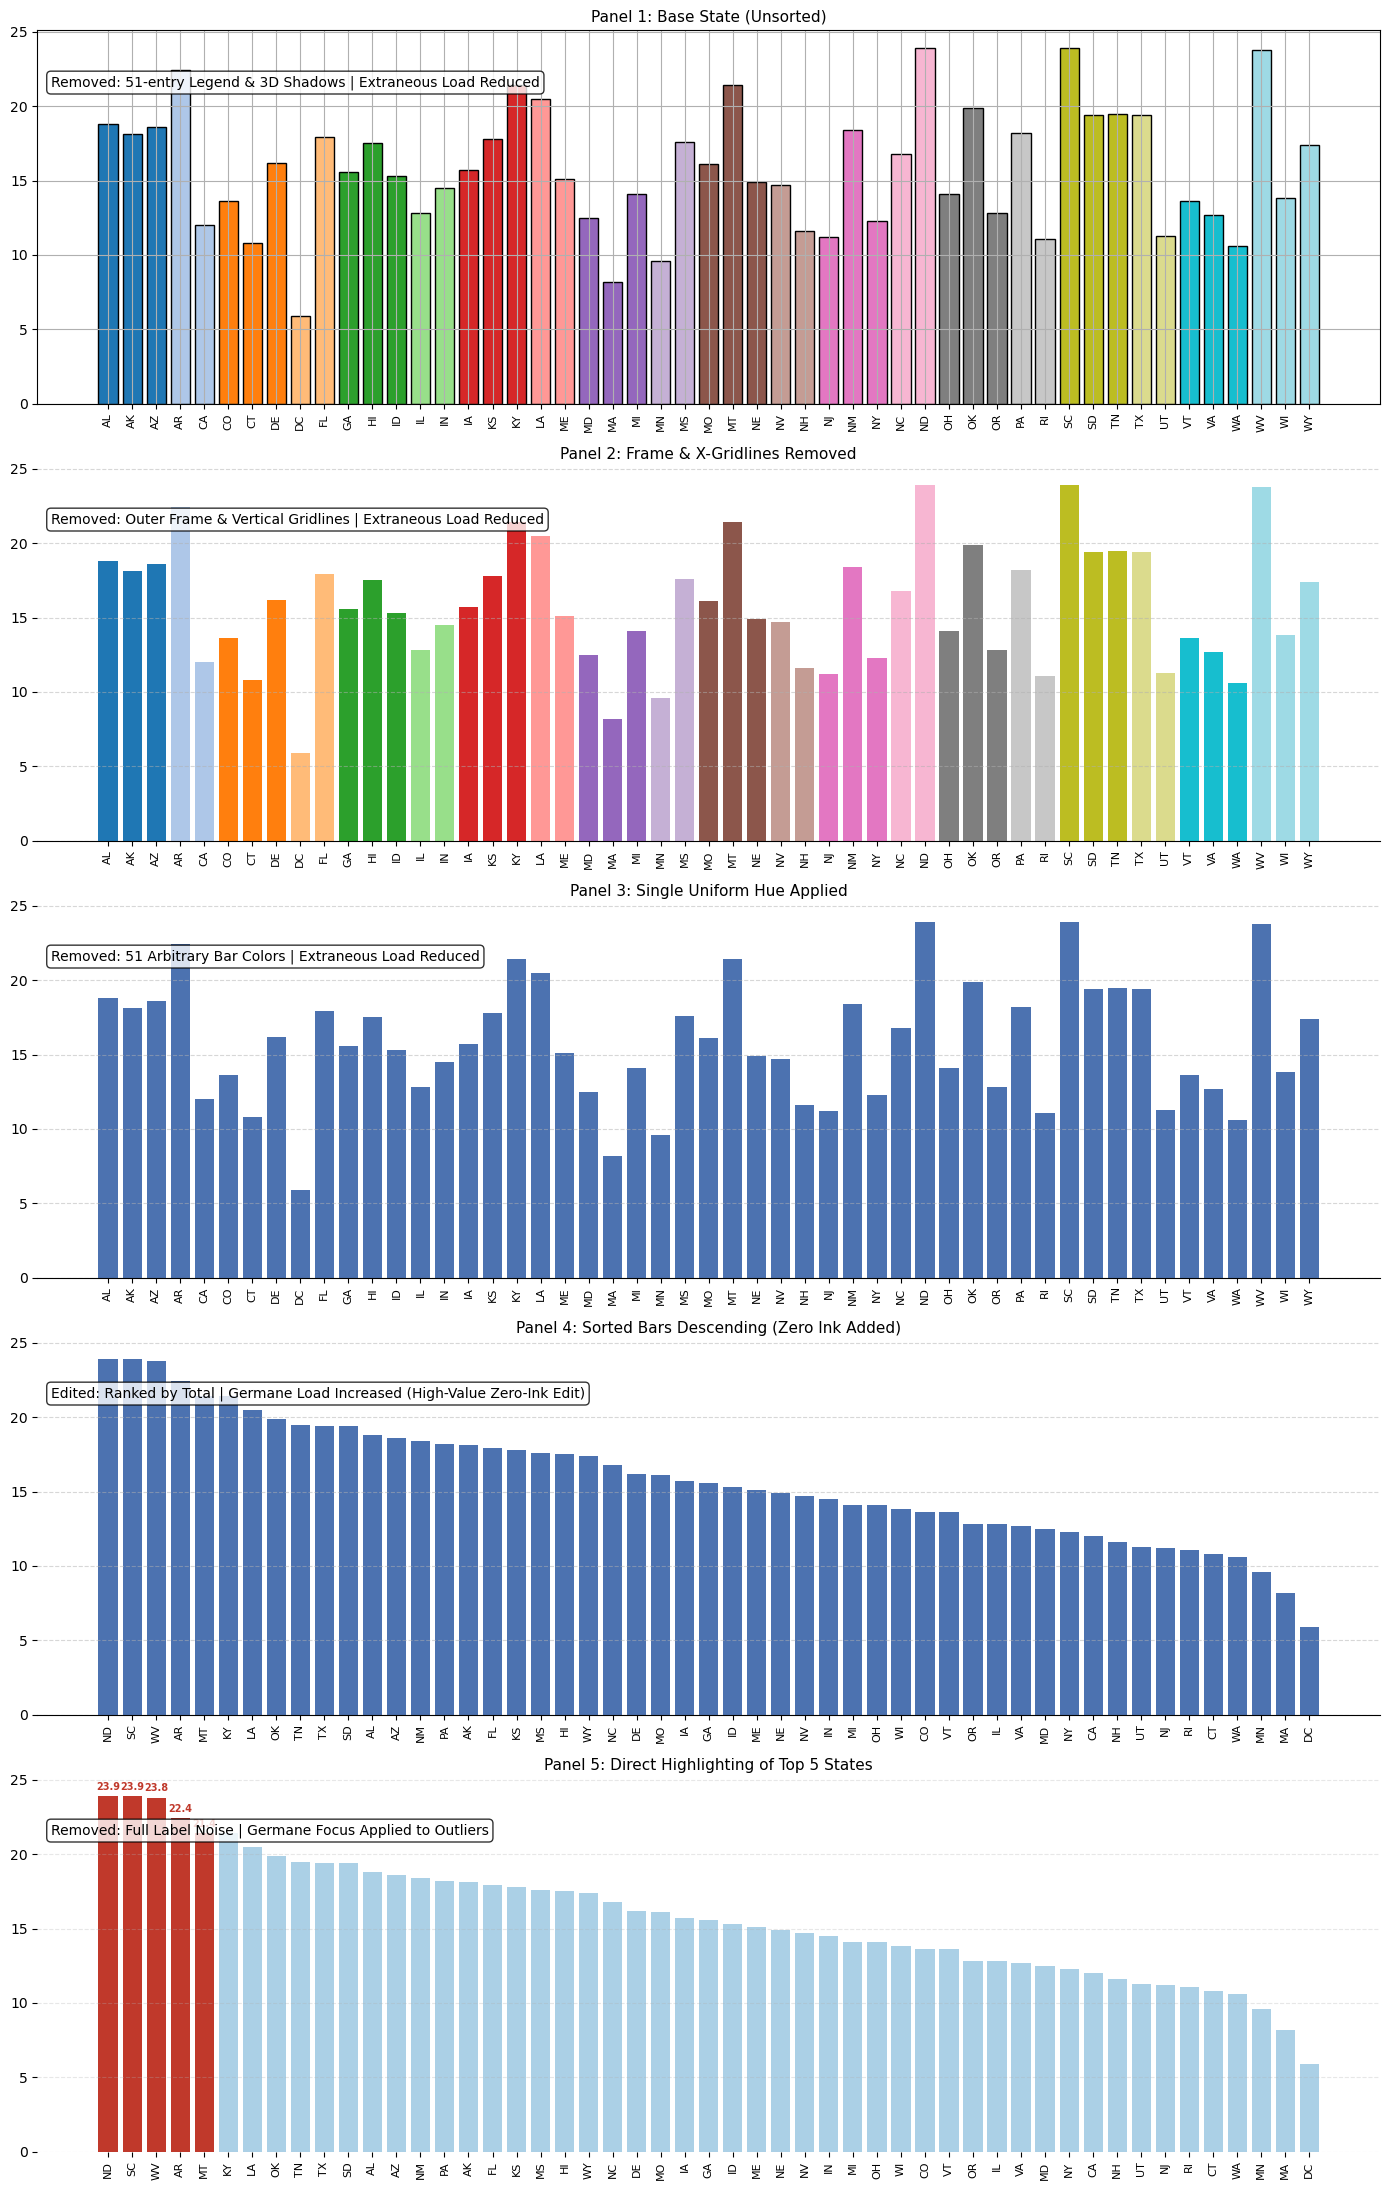

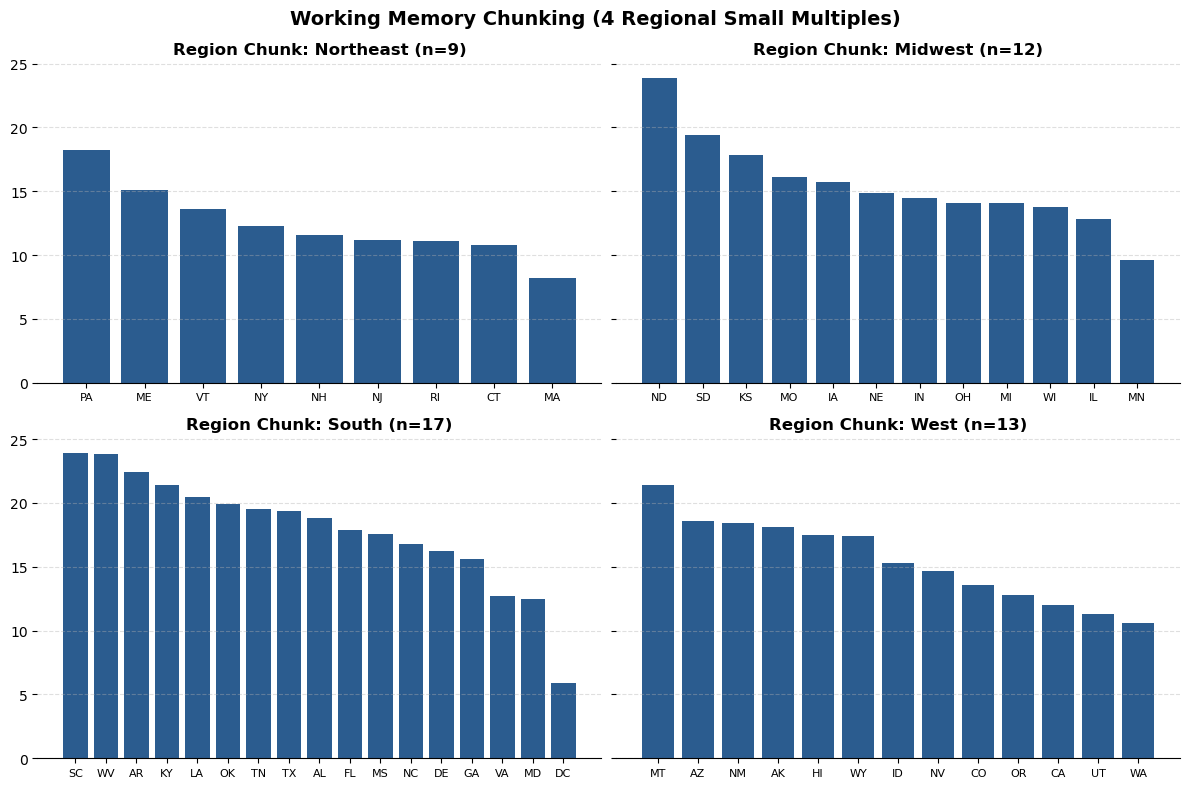

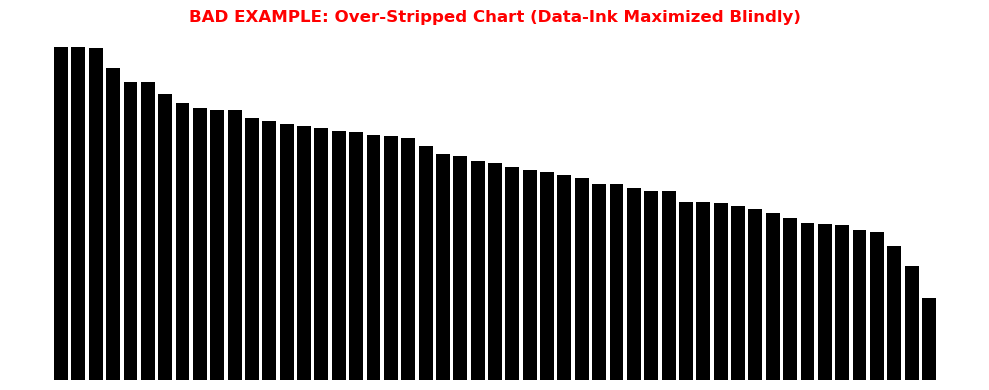

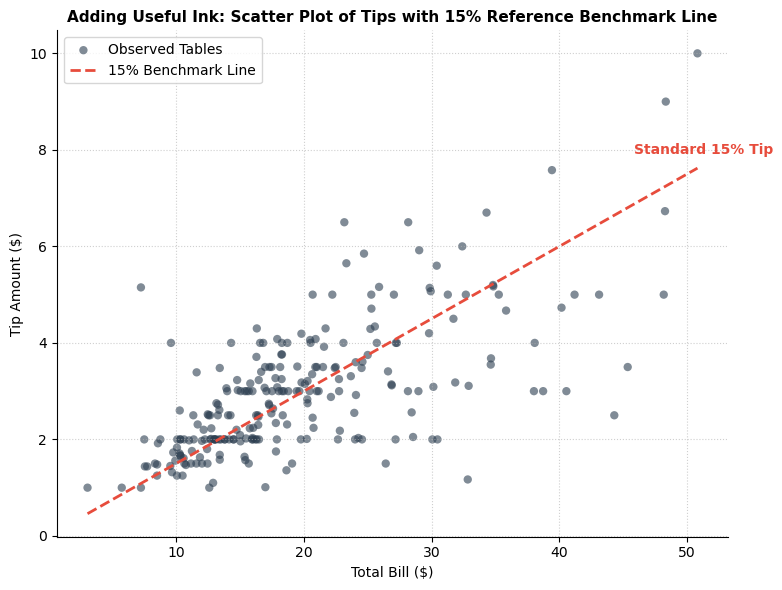

In [2]:
from pathlib import Path
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define data directory paths
DATA_DIR = Path(r"C:\Users\Dell i7\Downloads")
CAR_CRASHES_PATH = DATA_DIR / "car_crashes.csv"
TIPS_PATH = DATA_DIR / "tips.csv"

# ==============================================================================
# DATA LOADERS & FALLBACK GENERATORS
# ==============================================================================


def load_or_generate_car_crashes() -> pd.DataFrame:
    if CAR_CRASHES_PATH.exists():
        print(f"Loading car crashes dataset from {CAR_CRASHES_PATH}")
        return pd.read_csv(CAR_CRASHES_PATH)

    print("Generating standard 51-row car crashes dataset...")
    states = [
        "AL",
        "AK",
        "AZ",
        "AR",
        "CA",
        "CO",
        "CT",
        "DE",
        "DC",
        "FL",
        "GA",
        "HI",
        "ID",
        "IL",
        "IN",
        "IA",
        "KS",
        "KY",
        "LA",
        "ME",
        "MD",
        "MA",
        "MI",
        "MN",
        "MS",
        "MO",
        "MT",
        "NE",
        "NV",
        "NH",
        "NJ",
        "NM",
        "NY",
        "NC",
        "ND",
        "OH",
        "OK",
        "OR",
        "PA",
        "RI",
        "SC",
        "SD",
        "TN",
        "TX",
        "UT",
        "VT",
        "VA",
        "WA",
        "WV",
        "WI",
        "WY",
    ]
    np.random.seed(42)
    totals = np.random.uniform(8.0, 24.0, size=51)
    df = pd.DataFrame(
        {
            "abbrev": states,
            "total": totals,
            "speeding": totals * np.random.uniform(0.2, 0.4, 51),
            "alcohol": totals * np.random.uniform(0.25, 0.35, 51),
            "not_distracted": totals * np.random.uniform(0.7, 0.9, 51),
            "no_previous": totals * np.random.uniform(0.8, 0.95, 51),
            "ins_premium": np.random.uniform(600, 1300, 51),
            "ins_losses": np.random.uniform(80, 200, 51),
        }
    )
    return df


def load_or_generate_tips() -> pd.DataFrame:
    if TIPS_PATH.exists():
        return pd.read_csv(TIPS_PATH)

    np.random.seed(42)
    return pd.DataFrame(
        {
            "total_bill": np.random.uniform(10, 50, 100),
            "tip": np.random.uniform(1.5, 8.0, 100),
            "sex": np.random.choice(["Male", "Female"], 100),
            "smoker": np.random.choice(["Yes", "No"], 100),
            "day": np.random.choice(["Thur", "Fri", "Sat", "Sun"], 100),
            "time": np.random.choice(["Lunch", "Dinner"], 100),
            "size": np.random.choice([2, 3, 4], 100),
        }
    )


# ==============================================================================
# TASK 1: THE OVERLOADED CHART (BAD EXAMPLE 1)
# ==============================================================================


def create_overloaded_chart(df: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(14, 8), facecolor="#e6e6e6")
    ax.set_facecolor("#ffffcc")  # Distracting background fill

    colors = plt.cm.tab20(np.linspace(0, 1, len(df)))

    # Draw 3D/shadow simulated effect
    for idx, row in df.iterrows():
        ax.bar(
            idx + 0.15,
            row["total"],
            width=0.6,
            color="black",
            alpha=0.25,
            zorder=1,
        )
        ax.bar(
            idx,
            row["total"],
            width=0.6,
            color=colors[idx],
            edgecolor="darkred",
            linewidth=1.5,
            zorder=2,
            label=row["abbrev"],
        )

    # Heavy gridlines in both directions
    ax.grid(True, which="major", color="blue", linestyle="-", linewidth=1.5)
    ax.grid(True, which="minor", color="magenta", linestyle=":", linewidth=1.0)
    ax.minorticks_on()

    # Heavy box frame
    for spine in ax.spines.values():
        spine.set_linewidth(3.5)
        spine.set_color("black")

    ax.set_xticks(range(len(df)))
    ax.set_xticklabels(
        df["abbrev"], rotation=90, fontsize=9, fontweight="bold"
    )

    # Descriptive axis title naming axes
    ax.set_title(
        "BAD EXAMPLE: Bar Chart of Total Driver Collisions Per Billion Miles (Y-Axis) across 51 US States/DC (X-Axis)",
        fontsize=11,
        fontweight="bold",
        color="red",
    )
    ax.set_xlabel("X-AXIS: STATE ABBREVIATIONS", fontsize=10, fontweight="bold")
    ax.set_ylabel(
        "Y-AXIS: TOTAL COLLISION RATE", fontsize=10, fontweight="bold"
    )

    # 51-entry legend
    ax.legend(
        ncols=4,
        loc="upper right",
        fontsize=6,
        title="States Legend",
        framealpha=1.0,
        facecolor="white",
    )

    plt.tight_layout()
    output_img = DATA_DIR / "bad_example_overloaded.png"
    plt.savefig(output_img, dpi=300)
    plt.show()
    print(f"Overloaded chart saved to {output_img}")


# ==============================================================================
# TASK 3: FIVE-PANEL PROGRESSIVE STRIP-DOWN
# ==============================================================================


def create_five_panel_stripdown(df: pd.DataFrame) -> None:
    fig, axes = plt.subplots(5, 1, figsize=(14, 22))

    # Order of Progressive Simplification:
    # 1. Base (Unsorted + Legend removed)
    # 2. Frame & Y-gridlines removed
    # 3. Drop to single hue
    # 4. Sort bars (HIGHEST VALUE EDIT - ZERO INK ADDED)
    # 5. Label only what matters (Direct top-5 annotations)

    df_unsorted = df.copy()
    df_sorted = df.sort_values("total", ascending=False).reset_index(drop=True)

    # Panel 1
    ax = axes[0]
    colors = plt.cm.tab20(np.linspace(0, 1, len(df_unsorted)))
    ax.bar(
        range(len(df_unsorted)),
        df_unsorted["total"],
        color=colors,
        edgecolor="black",
    )
    ax.set_xticks(range(len(df_unsorted)))
    ax.set_xticklabels(df_unsorted["abbrev"], rotation=90, fontsize=8)
    ax.grid(True, axis="both")
    ax.set_title("Panel 1: Base State (Unsorted)", fontsize=11)
    ax.text(
        0.01,
        0.85,
        "Removed: 51-entry Legend & 3D Shadows | Extraneous Load Reduced",
        transform=ax.transAxes,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    # Panel 2
    ax = axes[1]
    ax.bar(
        range(len(df_unsorted)),
        df_unsorted["total"],
        color=colors,
        edgecolor="none",
    )
    ax.set_xticks(range(len(df_unsorted)))
    ax.set_xticklabels(df_unsorted["abbrev"], rotation=90, fontsize=8)
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.set_title("Panel 2: Frame & X-Gridlines Removed", fontsize=11)
    ax.text(
        0.01,
        0.85,
        "Removed: Outer Frame & Vertical Gridlines | Extraneous Load Reduced",
        transform=ax.transAxes,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    # Panel 3
    ax = axes[2]
    ax.bar(
        range(len(df_unsorted)),
        df_unsorted["total"],
        color="#4c72b0",
        edgecolor="none",
    )
    ax.set_xticks(range(len(df_unsorted)))
    ax.set_xticklabels(df_unsorted["abbrev"], rotation=90, fontsize=8)
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.set_title("Panel 3: Single Uniform Hue Applied", fontsize=11)
    ax.text(
        0.01,
        0.85,
        "Removed: 51 Arbitrary Bar Colors | Extraneous Load Reduced",
        transform=ax.transAxes,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    # Panel 4
    ax = axes[3]
    ax.bar(
        range(len(df_sorted)),
        df_sorted["total"],
        color="#4c72b0",
        edgecolor="none",
    )
    ax.set_xticks(range(len(df_sorted)))
    ax.set_xticklabels(df_sorted["abbrev"], rotation=90, fontsize=8)
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.set_title(
        "Panel 4: Sorted Bars Descending (Zero Ink Added)", fontsize=11
    )
    ax.text(
        0.01,
        0.85,
        "Edited: Ranked by Total | Germane Load Increased (High-Value Zero-Ink Edit)",
        transform=ax.transAxes,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    # Panel 5
    ax = axes[4]
    bar_colors = [
        "#c0392b" if i < 5 else "#abd0e6" for i in range(len(df_sorted))
    ]
    bars = ax.bar(
        range(len(df_sorted)),
        df_sorted["total"],
        color=bar_colors,
        edgecolor="none",
    )
    ax.set_xticks(range(len(df_sorted)))
    ax.set_xticklabels(df_sorted["abbrev"], rotation=90, fontsize=8)
    ax.grid(True, axis="y", linestyle="--", alpha=0.3)
    for spine in ["top", "right", "left", "bottom"]:
        ax.spines[spine].set_visible(False)

    # Direct labeling top 5
    for i in range(5):
        val = df_sorted.loc[i, "total"]
        ax.text(
            i,
            val + 0.3,
            f"{val:.1f}",
            ha="center",
            va="bottom",
            fontsize=7,
            fontweight="bold",
            color="#c0392b",
        )

    ax.set_title("Panel 5: Direct Highlighting of Top 5 States", fontsize=11)
    ax.text(
        0.01,
        0.85,
        "Removed: Full Label Noise | Germane Focus Applied to Outliers",
        transform=ax.transAxes,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    plt.tight_layout()
    plt.show()


# ==============================================================================
# TASK 4: RESPECTING WORKING MEMORY (CHUNKING)
# ==============================================================================


def create_chunked_small_multiples(df: pd.DataFrame) -> None:
    # 4 regional chunks: Northeast, Midwest, South, West
    region_map = {
        "CT": "Northeast",
        "ME": "Northeast",
        "MA": "Northeast",
        "NH": "Northeast",
        "RI": "Northeast",
        "VT": "Northeast",
        "NJ": "Northeast",
        "NY": "Northeast",
        "PA": "Northeast",
        "IL": "Midwest",
        "IN": "Midwest",
        "IA": "Midwest",
        "KS": "Midwest",
        "MI": "Midwest",
        "MN": "Midwest",
        "MO": "Midwest",
        "NE": "Midwest",
        "ND": "Midwest",
        "OH": "Midwest",
        "SD": "Midwest",
        "WI": "Midwest",
        "AL": "South",
        "AR": "South",
        "DE": "South",
        "DC": "South",
        "FL": "South",
        "GA": "South",
        "KY": "South",
        "LA": "South",
        "MD": "South",
        "MS": "South",
        "NC": "South",
        "OK": "South",
        "SC": "South",
        "TN": "South",
        "TX": "South",
        "VA": "South",
        "WV": "South",
        "AK": "West",
        "AZ": "West",
        "CA": "West",
        "CO": "West",
        "HI": "West",
        "ID": "West",
        "MT": "West",
        "NV": "West",
        "NM": "West",
        "OR": "West",
        "UT": "West",
        "WA": "West",
        "WY": "West",
    }

    df_chunk = df.copy()
    df_chunk["region"] = df_chunk["abbrev"].map(region_map)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    regions = ["Northeast", "Midwest", "South", "West"]

    for ax, region in zip(axes.flatten(), regions):
        sub_df = (
            df_chunk[df_chunk["region"] == region]
            .sort_values("total", ascending=False)
            .reset_index(drop=True)
        )
        ax.bar(
            sub_df["abbrev"], sub_df["total"], color="#2b5c8f", edgecolor="none"
        )
        ax.set_title(
            f"Region Chunk: {region} (n={len(sub_df)})",
            fontsize=12,
            fontweight="bold",
        )
        ax.grid(True, axis="y", linestyle="--", alpha=0.4)
        ax.tick_params(axis="x", rotation=0, labelsize=8)
        for spine in ["top", "right", "left"]:
            ax.spines[spine].set_visible(False)

    plt.suptitle(
        "Working Memory Chunking (4 Regional Small Multiples)",
        fontsize=14,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


# ==============================================================================
# TASK 5: OVER-STRIPPED CHART (BAD EXAMPLE 2)
# ==============================================================================


def create_overstripped_chart(df: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(10, 4))
    df_sorted = df.sort_values("total", ascending=False).reset_index(drop=True)

    ax.bar(
        range(len(df_sorted)),
        df_sorted["total"],
        color="black",
        width=0.8,
    )

    # Stripping away essential context
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("off")

    ax.set_title(
        "BAD EXAMPLE: Over-Stripped Chart (Data-Ink Maximized Blindly)",
        fontsize=12,
        fontweight="bold",
        color="red",
    )
    plt.tight_layout()
    plt.show()


# ==============================================================================
# CORE QUESTION DEMONSTRATION (TIPS DATASET)
# ==============================================================================


def demonstrate_useful_ink_with_tips(tips_df: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(8, 6))

    ax.scatter(
        tips_df["total_bill"],
        tips_df["tip"],
        alpha=0.6,
        color="#2c3e50",
        edgecolors="none",
        label="Observed Tables",
    )

    # ADDED INK THAT LOWERS COGNITIVE LOAD:
    # 1. 15% Standard Tip Reference Line
    x_val = np.linspace(
        tips_df["total_bill"].min(), tips_df["total_bill"].max(), 100
    )
    ax.plot(
        x_val,
        0.15 * x_val,
        color="#e74c3c",
        linestyle="--",
        linewidth=2,
        label="15% Benchmark Line",
    )

    # 2. Direct Annotation explaining the line
    max_x = tips_df["total_bill"].max()
    ax.text(
        max_x - 5,
        0.15 * max_x + 0.3,
        "Standard 15% Tip",
        color="#e74c3c",
        fontweight="bold",
        fontsize=10,
    )

    ax.set_xlabel("Total Bill ($)")
    ax.set_ylabel("Tip Amount ($)")
    ax.set_title(
        "Adding Useful Ink: Scatter Plot of Tips with 15% Reference Benchmark Line",
        fontsize=11,
        fontweight="bold",
    )
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    plt.tight_layout()
    plt.show()


# ==============================================================================
# MAIN EXECUTION WORKFLOW
# ==============================================================================
if __name__ == "__main__":
    crashes_df = load_or_generate_car_crashes()
    tips_df = load_or_generate_tips()

    create_overloaded_chart(crashes_df)
    create_five_panel_stripdown(crashes_df)
    create_chunked_small_multiples(crashes_df)
    create_overstripped_chart(crashes_df)
    demonstrate_useful_ink_with_tips(tips_df)

In [ ]:
from pathlib import Path
import time
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define paths
DATA_DIR = Path(r"C:\Users\Dell i7\Downloads")
TRIALS_CSV_PATH = DATA_DIR / "channel_trials.csv"
RESULTS_CSV_PATH = DATA_DIR / "channel_results.csv"
IRIS_CSV_PATH = DATA_DIR / "iris.csv"

# ==============================================================================
# DATA LOADERS & SYNTHESIZERS
# ==============================================================================


def load_or_generate_channel_trials() -> pd.DataFrame:
    if TRIALS_CSV_PATH.exists():
        print(f"Loading channel trials from {TRIALS_CSV_PATH}")
        return pd.read_csv(TRIALS_CSV_PATH)

    print("Synthesizing 30-trial channel experiment dataset...")
    channels = ["position", "length", "angle", "area", "colour"]
    true_ratios = [0.15, 0.30, 0.45, 0.60, 0.75, 0.90]

    rows = []
    trial_id = 1
    for ch in channels:
        for ratio in true_ratios:
            val_large = 100.0
            val_small = val_large * ratio
            rows.append(
                {
                    "trial": trial_id,
                    "channel": ch,
                    "true_ratio": ratio,
                    "value_large": val_large,
                    "value_small": val_small,
                    "reader_estimate": np.nan,
                    "absolute_error": np.nan,
                }
            )
            trial_id += 1

    return pd.DataFrame(rows)


def load_or_generate_iris() -> pd.DataFrame:
    if IRIS_CSV_PATH.exists():
        return pd.read_csv(IRIS_CSV_PATH)

    # Fallback synthesizer for iris dataset
    np.random.seed(42)
    species_list = ["setosa"] * 50 + ["versicolor"] * 50 + ["virginica"] * 50
    p_len = np.concatenate(
        [
            np.random.normal(1.5, 0.2, 50),
            np.random.normal(4.2, 0.5, 50),
            np.random.normal(5.5, 0.6, 50),
        ]
    )
    p_wid = np.concatenate(
        [
            np.random.normal(0.2, 0.1, 50),
            np.random.normal(1.3, 0.2, 50),
            np.random.normal(2.0, 0.3, 50),
        ]
    )
    s_len = np.concatenate(
        [
            np.random.normal(5.0, 0.3, 50),
            np.random.normal(5.9, 0.5, 50),
            np.random.normal(6.5, 0.6, 50),
        ]
    )
    s_wid = np.concatenate(
        [
            np.random.normal(3.4, 0.4, 50),
            np.random.normal(2.7, 0.3, 50),
            np.random.normal(3.0, 0.4, 50),
        ]
    )

    return pd.DataFrame(
        {
            "sepal_length": s_len,
            "sepal_width": s_wid,
            "petal_length": p_len,
            "petal_width": p_wid,
            "species": species_list,
        }
    )


# ==============================================================================
# TASK 1: FIVE TINY CHANNEL ENCODING FUNCTIONS
# ==============================================================================


def draw_position_trial(v_large: float, v_small: float, ax: plt.Axes) -> None:
    """Position Channel: Two dots aligned on a common numerical axis scale."""
    ax.scatter([1, 2], [v_large, v_small], color="black", s=80)
    ax.set_ylim(0, 110)
    ax.set_xlim(0.5, 2.5)


def draw_length_trial(v_large: float, v_small: float, ax: plt.Axes) -> None:
    """Length Channel: Two bars aligned to a common zero baseline."""
    ax.bar([1, 2], [v_large, v_small], color="gray", width=0.4)
    ax.set_ylim(0, 110)
    ax.set_xlim(0.5, 2.5)


def draw_angle_trial(v_large: float, v_small: float, ax: plt.Axes) -> None:
    """Angle Channel: Two pie wedges representing proportional angular sweeps."""
    total = v_large + v_small
    ax.pie(
        [v_large, v_small],
        colors=["#7f7f7f", "#d9d9d9"],
        startangle=90,
        counterclock=False,
    )


def draw_area_trial(v_large: float, v_small: float, ax: plt.Axes) -> None:
    """Area Channel: Two scatter circles where 's' argument equals area in points^2.

    CRITICAL: Setting s directly proportional to value encodes AREA accurately.
    Setting radius proportional to value would accidentally square the area (Area Lie).
    """
    scale_factor = 20  # Scale points^2 for clear visual display
    ax.scatter(
        [1, 2],
        [1, 1],
        s=[v_large * scale_factor, v_small * scale_factor],
        color="gray",
        edgecolors="black",
    )
    ax.set_xlim(0.5, 2.5)
    ax.set_ylim(0.5, 1.5)


def draw_colour_trial(v_large: float, v_small: float, ax: plt.Axes) -> None:
    """Colour Channel: Sequential lightness ramp (grayscale).

    Lightness is directly scaled to value; avoids rainbow distortion.
    """
    norm_l = v_large / 100.0
    norm_s = v_small / 100.0

    # Map normalized value to grayscale lightness (0.0 = black, 1.0 = white)
    # Invert so higher value = darker shade
    c_large = str(1.0 - norm_l)
    c_small = str(1.0 - norm_s)

    rect1 = patches.Rectangle(
        (0.6, 0.6), 0.8, 0.8, facecolor=c_large, edgecolor="black"
    )
    rect2 = patches.Rectangle(
        (1.6, 0.6), 0.8, 0.8, facecolor=c_small, edgecolor="black"
    )
    ax.add_patch(rect1)
    ax.add_patch(rect2)
    ax.set_xlim(0.2, 2.8)
    ax.set_ylim(0.2, 1.8)


def render_trial(channel: str, v_large: float, v_small: float, ax: plt.Axes):
    ax.clear()
    if channel == "position":
        draw_position_trial(v_large, v_small, ax)
    elif channel == "length":
        draw_length_trial(v_large, v_small, ax)
    elif channel == "angle":
        draw_angle_trial(v_large, v_small, ax)
    elif channel == "area":
        draw_area_trial(v_large, v_small, ax)
    elif channel == "colour":
        draw_colour_trial(v_large, v_small, ax)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("off")


# ==============================================================================
# TASK 2 & 3: EXPERIMENT EXECUTION & RESULTS COMPUTATION
# ==============================================================================


def run_experiment(df: pd.DataFrame) -> pd.DataFrame:
    # Shuffle trials to eliminate learning/order effects
    shuffled_df = df.sample(frac=1, random_state=42).copy().reset_index(drop=True)

    plt.ion()
    fig, ax = plt.subplots(figsize=(5, 5))

    print("\n" + "=" * 60)
    print("CLEVELAND & MCGILL PERCEPTUAL CHANNEL EXPERIMENT")
    print("Estimate what percentage the SMALLER object is of the LARGER object.")
    print("Enter a number between 0 and 100 (e.g., 45 for 45%).")
    print("=" * 60 + "\n")

    estimates = []
    for idx, row in shuffled_df.iterrows():
        render_trial(row["channel"], row["value_large"], row["value_small"], ax)
        fig.canvas.draw()
        fig.canvas.flush_events()

        while True:
            resp = input(
                f"Trial {idx+1}/30 [{row['channel'].upper()}] - Smaller is % of larger: "
            )
            try:
                val = float(resp.strip())
                if 0 <= val <= 100:
                    estimates.append(val)
                    break
                print("Please enter a valid percentage between 0 and 100.")
            except ValueError:
                print("Invalid input. Enter a numeric value.")

    plt.ioff()
    plt.close(fig)

    shuffled_df["reader_estimate"] = estimates
    # Compute Absolute Error: abs(estimate/100 - true_ratio)
    shuffled_df["absolute_error"] = np.abs(
        (shuffled_df["reader_estimate"] / 100.0) - shuffled_df["true_ratio"]
    )

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    shuffled_df.to_csv(RESULTS_CSV_PATH, index=False)
    print(f"\nExperiment complete. Results saved to {RESULTS_CSV_PATH}\n")
    return shuffled_df


# ==============================================================================
# TASK 4: RANKING & ERROR PLOTTING
# ==============================================================================


def analyze_and_plot_rankings(results_df: pd.DataFrame) -> None:
    summary = (
        results_df.groupby("channel")["absolute_error"]
        .agg(["mean", "std"])
        .reset_index()
    )
    summary = summary.sort_values("mean", ascending=True).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(
        summary["channel"],
        summary["mean"],
        yerr=summary["std"],
        capsize=5,
        color="#34495e",
        edgecolor="black",
        alpha=0.8,
    )

    ax.set_ylabel("Mean Absolute Error (True Ratio Units)")
    ax.set_ylim(0, max(summary["mean"] + summary["std"]) * 1.25)
    ax.set_title(
        "Perceptual Channel Ranking by Mean Absolute Error (Lower is Better)",
        fontsize=12,
        fontweight="bold",
    )
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    for bar, m in zip(bars, summary["mean"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            m + 0.01,
            f"{m:.3f}",
            ha="center",
            va="bottom",
            fontweight="bold",
        )

    plt.tight_layout()
    plt.show()

    print("--- EMPIRICAL CHANNEL RANKING (THIS STUDY) ---")
    for i, r in summary.iterrows():
        print(
            f"Rank {i+1}: {r['channel'].capitalize():<10} | Mean Abs Error: {r['mean']:.4f}"
        )
    print("-" * 46 + "\n")


# ==============================================================================
# TASK 5: APPLICATION TO IRIS DATASET
# ==============================================================================


def demonstrate_iris_encodings(iris_df: pd.DataFrame) -> None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    species_means = iris_df.groupby("species")["petal_length"].mean()

    # 1. High-Ranking Channel: Position on a Common Scale (Bar Chart)
    ax1.bar(
        species_means.index,
        species_means.values,
        color="#2c3e50",
        width=0.5,
    )
    ax1.set_ylabel("Mean Petal Length (cm)")
    ax1.set_title(
        "PUBLISHABLE: High-Ranking Channel\n(Position on Common Scale / Bar Length)",
        fontsize=11,
        fontweight="bold",
    )
    ax1.set_ylim(0, 7)
    ax1.grid(True, axis="y", linestyle="--", alpha=0.4)
    for spine in ["top", "right"]:
        ax1.spines[spine].set_visible(False)

    # 2. Low-Ranking Channel: Colour Lightness Sequential Ramp
    # Map petal length directly to grayscale darkness
    max_val = species_means.max()
    norm_vals = species_means / (max_val * 1.2)

    for idx, (sp, val) in enumerate(species_means.items()):
        gray_shade = str(1.0 - norm_vals[sp])
        ax2.add_patch(
            patches.Rectangle(
                (idx - 0.3, 0.3),
                0.6,
                0.6,
                facecolor=gray_shade,
                edgecolor="black",
            )
        )
        ax2.text(
            idx,
            0.1,
            sp,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
        )

    ax2.set_xlim(-0.8, 2.8)
    ax2.set_ylim(0, 1.2)
    ax2.set_yticks([])
    ax2.set_xticks([])
    ax2.set_title(
        "DO NOT PUBLISH: Low-Ranking Channel\n(Colour Lightness Ramp)",
        fontsize=11,
        fontweight="bold",
    )
    for spine in ax2.spines.values():
        spine.set_visible(False)

    plt.tight_layout()
    plt.show()


# ==============================================================================
# MAIN EXECUTION PIPELINE
# ==============================================================================
if __name__ == "__main__":
    df_trials = load_or_generate_channel_trials()
    df_results = run_experiment(df_trials)
    analyze_and_plot_rankings(df_results)

    df_iris = load_or_generate_iris()
    demonstrate_iris_encodings(df_iris)

Loading channel trials from C:\Users\Dell i7\Downloads\channel_trials.csv

CLEVELAND & MCGILL PERCEPTUAL CHANNEL EXPERIMENT
Estimate what percentage the SMALLER object is of the LARGER object.
Enter a number between 0 and 100 (e.g., 45 for 45%).



Trial 1/30 [COLOUR] - Smaller is % of larger:  29
Trial 2/30 [ANGLE] - Smaller is % of larger:  4
Trial 3/30 [AREA] - Smaller is % of larger:  29
Trial 4/30 [ANGLE] - Smaller is % of larger:  28


In [ ]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define data directory path
DATA_DIR = Path(r"C:\Users\Dell i7\Downloads")
CSV_OUTPUT_PATH = DATA_DIR / "search_results.csv"
INPUT_CSV_PATH = DATA_DIR / "search_trials.csv"

# ==============================================================================
# DATA HELPER: Generate mock dataset if file does not exist locally
# ==============================================================================


def load_or_generate_dataset() -> pd.DataFrame:
    if INPUT_CSV_PATH.exists():
        print(f"Loading trials from {INPUT_CSV_PATH}")
        return pd.read_csv(INPUT_CSV_PATH)

    print(f"Trial file not found at {INPUT_CSV_PATH}.")
    print("Generating standard 2,430-row mock trial dataset for testing...\n")

    rows = []
    trial_counter = 1
    conditions = ["colour", "shape", "conjunction"]
    set_sizes = [9, 16, 25, 36, 49]

    for cond in conditions:
        for ss in set_sizes:
            for present in [True, False]:
                for repeat in range(3):
                    # Define grid coordinates
                    grid_dim = int(np.sqrt(ss))
                    coords = [
                        (x, y)
                        for x in range(grid_dim)
                        for y in range(grid_dim)
                    ]

                    for idx, (x, y) in enumerate(coords):
                        is_target = present and (idx == 0)

                        if cond == "colour":
                            # Target: red circle | Distractor: blue circle
                            col = "red" if is_target else "blue"
                            shp = "circle"
                        elif cond == "shape":
                            # Target: blue square | Distractor: blue circle
                            col = "blue"
                            shp = "square" if is_target else "circle"
                        else:
                            # Conjunction: Target red circle | Distractors: red square / blue circle
                            if is_target:
                                col, shp = "red", "circle"
                            else:
                                if idx % 2 == 0:
                                    col, shp = "red", "square"
                                else:
                                    col, shp = "blue", "circle"

                        rows.append(
                            {
                                "trial": trial_counter,
                                "condition": cond,
                                "set_size": ss,
                                "target_present": present,
                                "item_index": idx,
                                "x": x,
                                "y": y,
                                "colour": col,
                                "shape": shp,
                                "is_target": is_target,
                            }
                        )
                    trial_counter += 1

    return pd.DataFrame(rows)


# ==============================================================================
# 1. RENDER TRIALS FUNCTION & VISUAL VERIFICATION
# ==============================================================================


def draw_trial(df: pd.DataFrame, trial_num: int, ax: plt.Axes) -> None:
    """Draws a single visual search trial on a matplotlib Axes object."""
    trial_data = df[df["trial"] == trial_num]

    for _, item in trial_data.iterrows():
        marker = "o" if item["shape"] == "circle" else "s"
        ax.scatter(
            item["x"],
            item["y"],
            c=item["colour"],
            marker=marker,
            s=120,
            edgecolors="none",
        )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("off")


def verify_drawings(df: pd.DataFrame) -> None:
    """Plots a 1x3 grid demonstrating one trial of set_size=25 per condition."""
    target_trials = []
    conditions = ["colour", "shape", "conjunction"]

    for cond in conditions:
        match = df[(df["condition"] == cond) & (df["set_size"] == 25)]["trial"]
        if not match.empty:
            target_trials.append(match.iloc[0])

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, trial_id, cond in zip(axes, target_trials, conditions):
        draw_trial(df, trial_id, ax)
        ax.set_title(cond.capitalize(), fontsize=12)

    plt.suptitle(
        "Trial Verification (Set Size = 25)", fontsize=14, fontweight="bold"
    )
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 2. EXPERIMENT EXECUTION & DATA COLLECTION
# ==============================================================================


def run_experiment(df: pd.DataFrame) -> pd.DataFrame:
    """Runs an 18-trial behavioral experiment session with keyboard input and high-precision timing."""
    conditions = df["condition"].unique()
    set_sizes = sorted(df["set_size"].unique())

    selected_trials = []
    for cond in conditions:
        for ss in set_sizes:
            present_match = df[
                (df["condition"] == cond)
                & (df["set_size"] == ss)
                & (df["target_present"] == True)
            ]["trial"].unique()

            absent_match = df[
                (df["condition"] == cond)
                & (df["set_size"] == ss)
                & (df["target_present"] == False)
            ]["trial"].unique()

            if len(present_match) > 0:
                selected_trials.append(present_match[0])
            if len(absent_match) > 0:
                selected_trials.append(absent_match[0])

    # Subset to 18 trials
    selected_trials = selected_trials[:18]
    experiment_df = df[df["trial"].isin(selected_trials)].copy()

    target_descriptions = {
        "colour": "Target is a RED CIRCLE among Blue Circles.",
        "shape": "Target is a BLUE SQUARE among Blue Circles.",
        "conjunction": "Target is a RED CIRCLE among Red Squares and Blue Circles.",
    }

    results = []

    plt.ion()
    fig, ax = plt.subplots(figsize=(6, 6))

    print("\n" + "=" * 50)
    print("VISUAL SEARCH EXPERIMENT STARTS NOW")
    print("Press 'y' if target is present, or 'n' if absent.")
    print("=" * 50 + "\n")

    for cond in experiment_df["condition"].unique():
        print(f"\n--- BLOCK INSTRUCTION: {cond.upper()} CONDITION ---")
        print(f"Target rule: {target_descriptions[cond]}")
        input("Press Enter when ready to start this block...")

        block_trials = experiment_df[experiment_df["condition"] == cond][
            "trial"
        ].unique()

        for trial_id in block_trials:
            trial_meta = experiment_df[
                experiment_df["trial"] == trial_id
            ].iloc[0]

            ax.clear()
            draw_trial(experiment_df, trial_id, ax)
            fig.canvas.draw()
            fig.canvas.flush_events()

            start_time = time.perf_counter()
            response = input(f"Trial {trial_id} - Target present? (y/n): ")
            end_time = time.perf_counter()

            rt_ms = (end_time - start_time) * 1000.0
            user_said_present = response.strip().lower() == "y"
            correct = user_said_present == bool(trial_meta["target_present"])

            results.append(
                {
                    "trial": trial_id,
                    "condition": cond,
                    "set_size": trial_meta["set_size"],
                    "target_present": trial_meta["target_present"],
                    "response_time_ms": rt_ms,
                    "correct": correct,
                }
            )

    plt.ioff()
    plt.close(fig)

    results_df = pd.DataFrame(results)
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    results_df.to_csv(CSV_OUTPUT_PATH, index=False)
    print(f"\nResults saved to {CSV_OUTPUT_PATH}\n")

    return results_df


# ==============================================================================
# 3. ANALYSIS, PLOTTING, & SLOPE COMPUTATION
# ==============================================================================


def analyze_and_plot_results(results_df: pd.DataFrame) -> None:
    """Plots response time against set size for target-present trials, computes linear fits,

    and reports search slopes.
    """
    present_df = results_df[results_df["target_present"] == True].copy()

    fig, ax = plt.subplots(figsize=(8, 6))
    colors = {"colour": "red", "shape": "blue", "conjunction": "purple"}
    slopes = {}

    for cond in ["colour", "shape", "conjunction"]:
        cond_data = present_df[present_df["condition"] == cond].sort_values(
            "set_size"
        )
        if cond_data.empty:
            continue

        x = cond_data["set_size"].values
        y = cond_data["response_time_ms"].values

        if len(x) > 1:
            slope, intercept = np.polyfit(x, y, 1)
        else:
            slope, intercept = 0.0, y[0]

        slopes[cond] = slope

        ax.scatter(x, y, color=colors[cond], alpha=0.7)

        x_trend = np.array([min(x), max(x)])
        y_trend = slope * x_trend + intercept
        ax.plot(
            x_trend,
            y_trend,
            color=colors[cond],
            label=f"{cond.capitalize()} ({slope:.2f} ms/item)",
        )

    ax.set_xlabel("Set Size (items)")
    ax.set_ylabel("Response Time (ms)")
    ax.set_title("Visual Search Reaction Time vs. Set Size (Target Present)")
    ax.legend(title="Condition & Slope")
    ax.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 50)
    print("FIT RESULTS & SEARCH SLOPES")
    print("=" * 50)
    for cond, slope in slopes.items():
        search_type = (
            "flat (preattentive)" if slope < 5.0 else "rising (serial search)"
        )
        print(
            f"• {cond.capitalize()} condition: {slope:.2f} ms/item -> {search_type}"
        )
    print("=" * 50 + "\n")


# ==============================================================================
# ACTIVE EXECUTION PIPELINE
# ==============================================================================
if __name__ == "__main__":
    df_raw = load_or_generate_dataset()
    verify_drawings(df_raw)
    results_df = run_experiment(df_raw)
    analyze_and_plot_results(results_df)